In [65]:
from _test_utils import TestLogger
from PicoTest import Pico
import numpy as np
import matplotlib.pyplot as plt
import time
logger = TestLogger()
#connect and initialize Pico
pico = Pico(logger=logger)
pico.initialize()
if pico.isConnected:
    print('Pico is connected.')
else:
    print('Error Pico NOT connected.')

Pico is connected.


In [2]:
pico.openChannel('C1')

'e\nset_gpio_cfg 96 1\nset_gpio 0i\n\n'

['e\n', '\n']

'e\nset_gpio_cfg 96 1\nset_gpio 96i\n\n'

measure takes 3.1696271709997745seconds
C1 - Average Resistance: 1.013e+04 Ohm, Error: 89.87%, Forward CV: 0.09%, Reverse CV: 0.06% 
C2 - Average Resistance: 1.013e+04 Ohm, Error: 89.87%, Forward CV: 0.10%, Reverse CV: 0.06% 
C3 - Average Resistance: 1.013e+04 Ohm, Error: 89.87%, Forward CV: 0.09%, Reverse CV: 0.07% 
C4 - Average Resistance: 1.014e+04 Ohm, Error: 89.86%, Forward CV: 0.08%, Reverse CV: 0.07% 


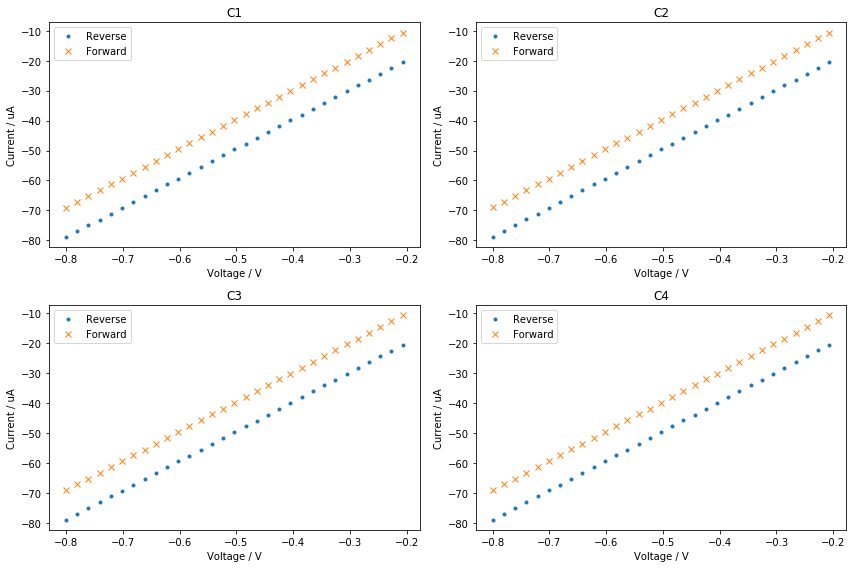

In [67]:
sc = """e
var c
var p
var f
var r
set_pgstat_chan 0
set_pgstat_mode 3
set_max_bandwidth 400
set_autoranging 100u 100u
cell_on
meas_loop_swv p c f r -800m -200m 20m 50m 100
	pck_start
	pck_add p
	pck_add f    
	pck_add r
	pck_end
endloop
on_finished:
cell_off

"""
datas=[]
channels = ['C1','C2','C3','C4']
channelError = []
resistor = 100e3
for channel in channels:
    pico.openChannel(channel)
    t0=time.perf_counter()
    res = pico.runScript(sc,parseValue=True)
    print(f'measure takes {time.perf_counter() - t0}seconds')
    p = np.array([i[0] for i in res[1][0]])
    f = np.array([i[1] for i in res[1][0]]) + 1e-12
    r = np.array([i[2] for i in res[1][0]]) + 1e-12
    datas.append([p,f,r])
    Rr = np.array(p) / np.array(r) 
    Rf = (np.array(p)+0.1) / np.array(f)  
    Rravg = Rr.mean()
    Rfavg = Rf.mean()
    RrCV = Rr.std(ddof=1) / Rravg
    RfCV = Rf.std(ddof=1) / Rfavg
    Rcalc =(Rravg+Rfavg)/2
    error = abs(Rcalc - resistor)/resistor
    channelError.append((Rcalc,error,RfCV,RrCV))

fig,axes = plt.subplots(2,2,figsize=(12,8))
axes = [i for j in axes for i in j]
for cn, (p,f,r),(Rcalc,error,RfCV,RrCV), ax in zip(channels,datas,channelError,axes):
    ax.plot(p,r*1e6,'.',label='Reverse')
    ax.plot(p,f*1e6,'x',label='Forward')
    ax.set_title(cn)
    ax.legend()
    ax.set_ylabel('Current / uA')
    ax.set_xlabel('Voltage / V')
    print(f'{cn} - Average Resistance: {Rcalc:.4g} Ohm, Error: {error:.2%}, Forward CV: {RfCV:.2%}, Reverse CV: {RrCV:.2%} ')
plt.tight_layout()
plt.show()
    

In [58]:
p,f,r = datas[0]

In [59]:
len(p)

10

In [60]:
(r*1e7)

array([-789.59647, -719.03671, -650.71711, -581.83739, -512.95771,
       -444.07803, -374.07831, -305.75861, -236.87893, -167.43924])

In [61]:
f*1e7

array([-690.47695, -621.59719, -552.15751, -483.83783, -414.39815,
       -345.51843, -276.63877, -207.19907, -138.87937,  -69.43968])

In [36]:
(p*1000).astype(int)

array([-199, -269, -339, -409, -479, -549, -619, -689, -759, -829])

In [13]:
R = (p/r).mean()

In [15]:
r*R*1000

array([-804.50489747, -781.22711271, -761.35577568, -740.91668384,
       -720.477592  , -701.17409087, -680.16720367, -661.9991716 ,
       -642.12783456, -621.68874272, -602.38516049, -581.94606865,
       -563.21024122, -542.77114938, -522.89981234, -503.59627066,
       -483.15713827, -464.42135139, -444.55001436, -424.11092252,
       -404.80734028, -384.368289  , -365.63246157, -345.19336973,
       -325.32205297, -306.01845046, -285.57937889, -266.84355146,
       -245.8367251 , -226.53314286, -206.6618261 ])

In [16]:
f*R*1000

array([-702.87727418, -681.30267273, -660.86366199, -641.56003921,
       -621.12094737, -601.24965088, -581.94606865, -562.07473161,
       -542.77114938, -521.76434329, -502.46076106, -483.15713827,
       -462.71808698, -443.98225955, -422.97541291, -403.67187123,
       -384.368289  , -363.92919716, -345.19336973, -323.61880883,
       -304.88296113, -285.01162409, -265.14028705, -246.4044799 ,
       -224.82989873, -206.09405102, -186.22273426, -166.35140736,
       -147.04782513, -126.04099876, -107.3051612 ])

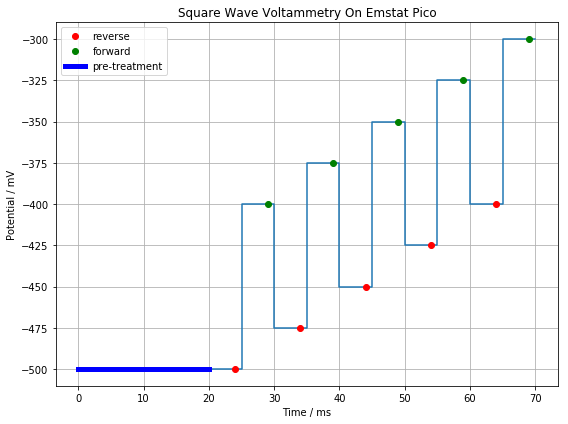

In [146]:
#plot SWV voltage curve
Hz = 100
start = -500
end = -400
step = 25
amplitude = 50
preT = 20
preV = -500
scanT = [0,preT]
scanV = [preV,preV]
V = start
tStep = 1000 / Hz
while True:
    tEnd = scanT[-1]
    scanT.extend([tEnd, tEnd + tStep/2, tEnd+tStep/2,tEnd+tStep ])
    scanV.extend([V,V,V+amplitude*2,V+amplitude*2 ])
    
    if (end>start and V >= end) or (end<start and V<=end):
        break
    V += step
fig,ax = plt.subplots(figsize=(8,6))
ax.set_title('Square Wave Voltammetry On Emstat Pico')
ax.plot(scanT,scanV)
ax.plot([i for i in range(24,65,10)],[j for j in range(-500,-391,25)],'ro',label='reverse')
ax.plot([i for i in range(29,70,10)],[j for j in range(-400,-299,25)],'go',label='forward')
ax.plot([0,preT],[preV,preV],'blue',linewidth=5,label='pre-treatment')
ax.set_xlabel('Time / ms')
ax.set_ylabel('Potential / mV')
ax.set_xticks([i*10 for i in range(8)])
ax.grid(True)
ax.legend()
plt.tight_layout()
